## 1. Data acquisition
 "Dataset: APTOS 2019 retina images (3,662), from Kaggle."

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q --upgrade kaggle
!kaggle datasets list -s "aptos 2019"

ref                                                          title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
mariaherrerot/aptos2019                                      APTOS-2019 dataset                                   8602506535  2021-11-17 12:04:06.840000          40503        100  0.5294118        
subhajeetdas/aptos-2019-jpg                                  APTOS 2019 (JPG)                                     3023642620  2025-02-24 12:28:31.247000           1000          9  1                
sovitrath/diabetic-retinopathy-224x224-gaussian-filtered     Diabetic Retinopathy 224x224 Gaussian Filtered        447582906  2020-02-18 02:33:27.540000          28911        258  0.88235295       
sovitrath/

In [ ]:
!kaggle datasets download -d sovitrath/diabetic-retinopathy-224x224-2019-data
!unzip -q -o diabetic-retinopathy-224x224-2019-data.zip -d data_raw
!ls data_raw

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data
License(s): CC0-1.0
diabetic-retinopathy-224x224-2019-data.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data_raw/colored_images/Mild/0024cdab0c1e.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: colored_images	train.csv


In [ ]:
import os
for root, dirs, files in os.walk("/content/data_raw"):
    print(root, "->", len(dirs), "folders,", len(files), "files")
    if root.count(os.sep) >= 4:
        dirs.clear()

/content/data_raw -> 1 folders, 1 files
/content/data_raw/colored_images -> 5 folders, 0 files
/content/data_raw/colored_images/Severe -> 0 folders, 193 files
/content/data_raw/colored_images/No_DR -> 0 folders, 1805 files
/content/data_raw/colored_images/Proliferate_DR -> 0 folders, 295 files
/content/data_raw/colored_images/Mild -> 0 folders, 370 files
/content/data_raw/colored_images/Moderate -> 0 folders, 999 files


File: 9f37c98b8187.png
Shape: (224, 224, 3)
Min/Max: 1 252
Top-left pixel (R,G,B): [4 4 6]


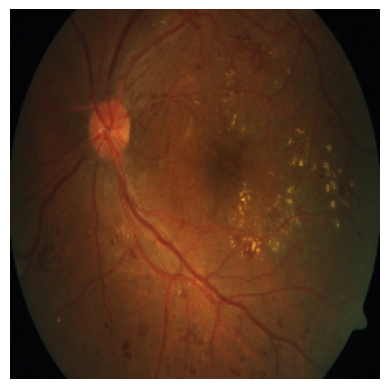

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

path = "/content/data_raw/colored_images/Severe/"
first_file = os.listdir(path)[0]

img = Image.open(path + first_file)
arr = np.array(img)

print("File:", first_file)
print("Shape:", arr.shape)
print("Min/Max:", arr.min(), arr.max())
print("Top-left pixel (R,G,B):", arr[0, 0])

plt.imshow(img)
plt.axis("off")
plt.show()

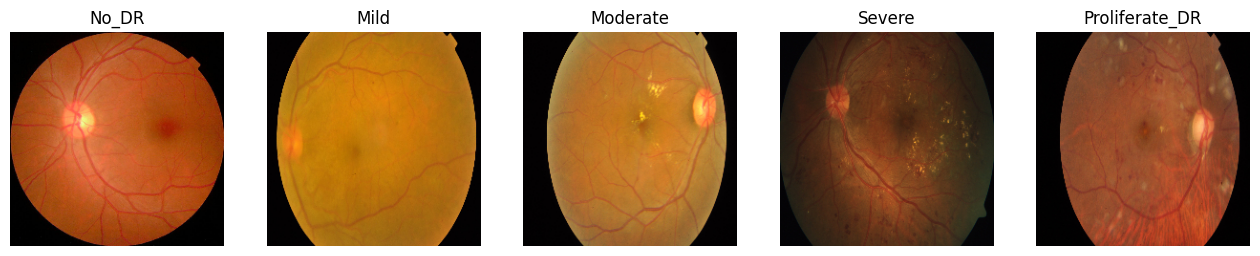

In [ ]:
base = "/content/data_raw/colored_images/"
classes = ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, c in zip(axes, classes):
    f = os.listdir(base + c)[0]
    ax.imshow(Image.open(base + c + "/" + f))
    ax.set_title(c)
    ax.axis("off")
plt.show()

## 2. Data Processing
Group the 5 grades into 3 classes, split 70/15/15 with stratify, resize to 224x224, normalize, and augment the training images only.

In [ ]:
import os
import pandas as pd

base = "/content/data_raw/colored_images/"
group = {
    "No_DR": "No_DR",
    "Mild": "Mild_Moderate",
    "Moderate": "Mild_Moderate",
    "Severe": "Severe_Proliferative",
    "Proliferate_DR": "Severe_Proliferative",
}

rows = []
for folder, g in group.items():
    for f in os.listdir(base + folder):
        rows.append({"path": base + folder + "/" + f, "original": folder, "label": g})

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())
df.head()

(3662, 3)
label
No_DR                   1805
Mild_Moderate           1369
Severe_Proliferative     488
Name: count, dtype: int64


,path,original,label
0,/content/data_raw/colored_images/No_DR/4cde860...,No_DR,No_DR
1,/content/data_raw/colored_images/No_DR/2cdcc91...,No_DR,No_DR
2,/content/data_raw/colored_images/No_DR/aa8a1e8...,No_DR,No_DR
3,/content/data_raw/colored_images/No_DR/e81f4a2...,No_DR,No_DR
4,/content/data_raw/colored_images/No_DR/25b4080...,No_DR,No_DR


In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

print("Train:", len(train_df), " Val:", len(val_df), " Test:", len(test_df))
print(test_df["label"].value_counts())

Train: 2563  Val: 549  Test: 550
label
No_DR                   271
Mild_Moderate           206
Severe_Proliferative     73
Name: count, dtype: int64


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH = 32
class_names = sorted(df["label"].unique())
print(class_names)

label_to_idx = {c: i for i, c in enumerate(class_names)}

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)          # safety resize
    return img, label

def make_ds(frame, training):
    paths = frame["path"].values
    labels = frame["label"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df, training=False)
test_ds  = make_ds(test_df, training=False)

# augmentation: only applied to the training set, inside the model later
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.1),
], name="augment")

['Mild_Moderate', 'No_DR', 'Severe_Proliferative']


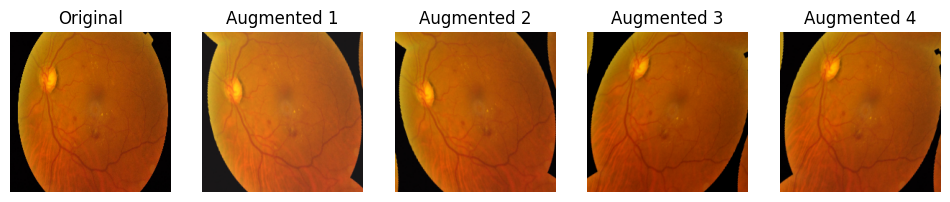

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))
img = images[0:1]

plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1)
plt.imshow(img[0].numpy().astype("uint8")); plt.title("Original"); plt.axis("off")
for i in range(4):
    plt.subplot(1, 5, i + 2)
    plt.imshow(augment(img, training=True)[0].numpy().astype("uint8"))
    plt.title(f"Augmented {i+1}"); plt.axis("off")
plt.show()

## 3. Model Creation
Transfer learning with a frozen MobileNetV2, plus dropout, L2 regularization, class weights, the Adam optimizer, and early stopping.

In [ ]:
from tensorflow.keras import regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False   # freeze the teller

inputs = tf.keras.Input(shape=(224, 224, 3))
x = augment(inputs)                      # only active during training
x = preprocess_input(x)                  # scales pixels to -1..1
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation="softmax",
                       kernel_regularizer=regularizers.l2(1e-4))(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

y_train = train_df["label"].map(label_to_idx).values
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(0.8917884481558803), 1: np.float64(0.6764317761942465), 2: np.float64(2.4980506822612085)}


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=15, class_weight=class_weight,
                    callbacks=[early_stop])


Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 23s 164ms/step - accuracy: 0.6137 - loss: 0.9300 - val_accuracy: 0.7905 - val_loss: 0.4939
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 97ms/step - accuracy: 0.7409 - loss: 0.6670 - val_accuracy: 0.7832 - val_loss: 0.4702
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 84ms/step - accuracy: 0.7651 - loss: 0.5962 - val_accuracy: 0.7832 - val_loss: 0.4573
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.7905 - loss: 0.5526 - val_accuracy: 0.7341 - val_loss: 0.5636
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.7967 - loss: 0.5486 - val_accuracy: 0.7687 - val_loss: 0.5021
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.7948 - loss: 0.5348 - val_accuracy: 0.8233 - val_loss: 0.4088
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.8053 - loss: 0.5137 - val_accuracy: 0.8160 - val_loss: 0.4201
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 0.8209 - loss: 0.4849 - val_accuracy: 0.8033

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 142ms/step
                      precision    recall  f1-score   support

       Mild_Moderate      0.827     0.835     0.831       206
               No_DR      0.971     0.974     0.972       271
Severe_Proliferative      0.629     0.603     0.615        73

            accuracy                          0.873       550
           macro avg      0.809     0.804     0.806       550
        weighted avg      0.871     0.873     0.872       550

Macro-F1: 0.806


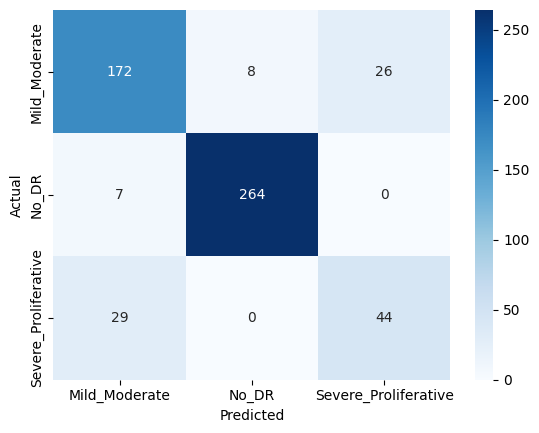

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.8727 - loss: 0.3477
Test loss: 0.348  Test accuracy: 0.873


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 3))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", round(test_loss, 3), " Test accuracy:", round(test_acc, 3))

## 4. Fine-Tuning
Unfreeze the top 30 layers of MobileNetV2 and train again with a very small learning rate.

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True)

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=15,
                       class_weight=class_weight, callbacks=[early_stop_ft])

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 113ms/step - accuracy: 0.6773 - loss: 0.8043 - val_accuracy: 0.8197 - val_loss: 0.4187
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 112ms/step - accuracy: 0.7616 - loss: 0.6037 - val_accuracy: 0.8233 - val_loss: 0.4031
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.7694 - loss: 0.5674 - val_accuracy: 0.8197 - val_loss: 0.3763
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 101ms/step - accuracy: 0.7987 - loss: 0.5267 - val_accuracy: 0.8470 - val_loss: 0.3584
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.8014 - loss: 0.5163 - val_accuracy: 0.8452 - val_loss: 0.3555
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 89ms/step - accuracy: 0.8088 - loss: 0.4916 - val_accuracy: 0.8525 - val_loss: 0.3475
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.8217 - loss: 0.4867 - val_accuracy: 0.8525 - val_loss: 0.3494
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.8268 - loss: 0.4670 - val_accuracy: 0.857

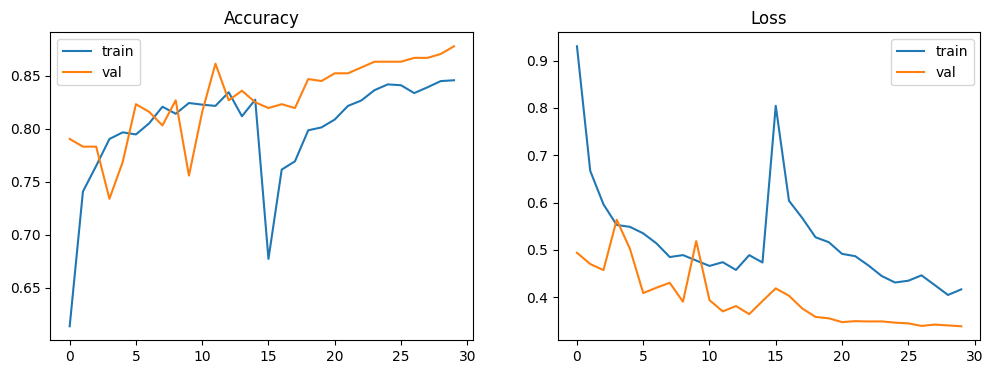

In [ ]:
acc = history.history["accuracy"] + history_ft.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
loss = history.history["loss"] + history_ft.history["loss"]
val_loss = history.history["val_loss"] + history_ft.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val"); ax[1].set_title("Loss"); ax[1].legend()
plt.show()

## 5. Model Testing
Evaluate on the unseen test set with accuracy, loss, precision, recall, F1, macro-F1, and a confusion matrix.

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step
                      precision    recall  f1-score   support

       Mild_Moderate      0.786     0.893     0.836       206
               No_DR      0.970     0.970     0.970       271
Severe_Proliferative      0.689     0.425     0.525        73

            accuracy                          0.869       550
           macro avg      0.815     0.763     0.777       550
        weighted avg      0.864     0.869     0.861       550

Macro-F1: 0.777


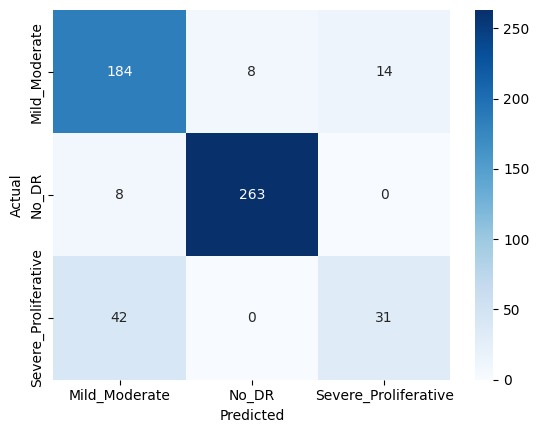

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8691 - loss: 0.3643
Test loss: 0.364 Test accuracy: 0.869


In [ ]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 3))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", round(test_loss, 3), "Test accuracy:", round(test_acc, 3))

**Result:** Fine-tuning lowered validation loss from about 0.364 to 0.339, so I kept the fine-tuned model. On the test set, macro-F1 went from 0.806 to 0.777 because Severe recall fell from 0.603 to 0.425 (31 of 73 caught). No Severe image was predicted as No_DR. The test set has only 73 Severe images, so this result is noisy. Threshold tuning chose a weight of 1.0, so it gave no gain here.

## 6. Threshold Tuning
Search for the best boost for the rare Severe class, chosen on the validation set.

18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step
1.0 0.8006
1.25 0.799
1.5 0.7994
1.75 0.7885
2.0 0.7953
2.25 0.7852
2.5 0.7798
2.75 0.7779
3.0 0.7791
3.25 0.7747
3.5 0.7692
3.75 0.767
4.0 0.7692
Best Severe weight: 1.0 Val macro-F1: 0.8006
                      precision    recall  f1-score   support

       Mild_Moderate      0.786     0.893     0.836       206
               No_DR      0.970     0.970     0.970       271
Severe_Proliferative      0.689     0.425     0.525        73

            accuracy                          0.869       550
           macro avg      0.815     0.763     0.777       550
        weighted avg      0.864     0.869     0.861       550

Test macro-F1 with threshold: 0.777


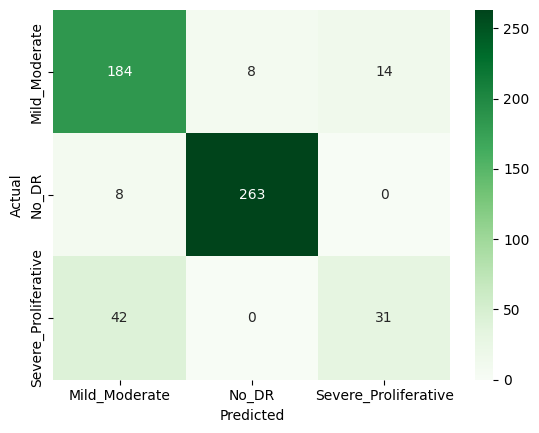

In [ ]:
y_val = np.concatenate([y.numpy() for _, y in val_ds])
p_val = model.predict(val_ds)

best_w, best_f1 = 1.0, 0
for w in np.arange(1.0, 4.01, 0.25):
    pred = np.argmax(p_val * np.array([1, 1, w]), axis=1)
    f = f1_score(y_val, pred, average="macro")
    print(round(w, 2), round(f, 4))
    if f > best_f1:
        best_w, best_f1 = float(w), f
print("Best Severe weight:", best_w, "Val macro-F1:", round(best_f1, 4))

SEVERE_WEIGHT = best_w
pred_t = np.argmax(y_prob * np.array([1, 1, SEVERE_WEIGHT]), axis=1)
print(classification_report(y_true, pred_t, target_names=class_names, digits=3))
print("Test macro-F1 with threshold:", round(f1_score(y_true, pred_t, average="macro"), 3))
cm2 = confusion_matrix(y_true, pred_t)
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

## 7. Data Visualizations
Three charts of the dataset, each with an interpretation.

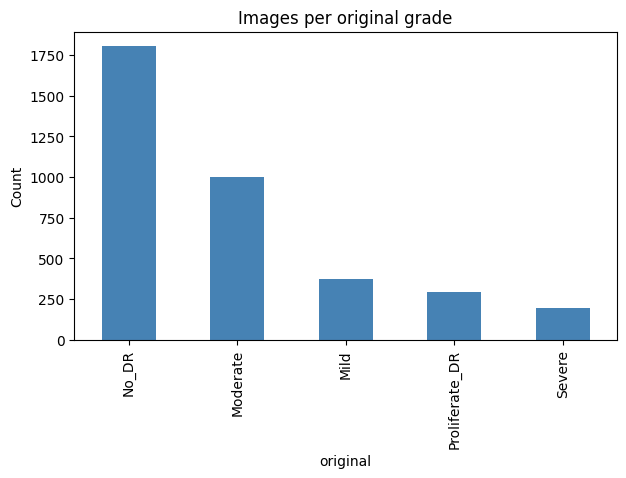

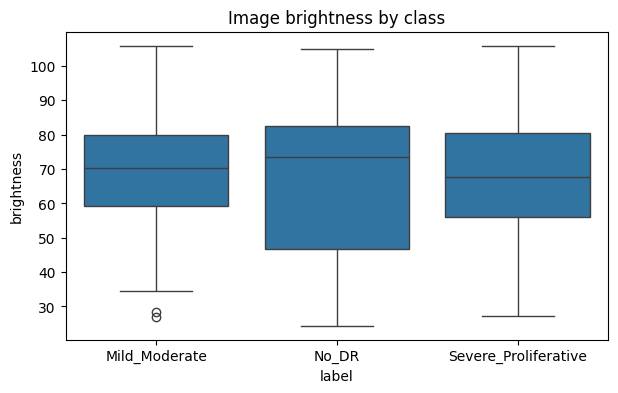

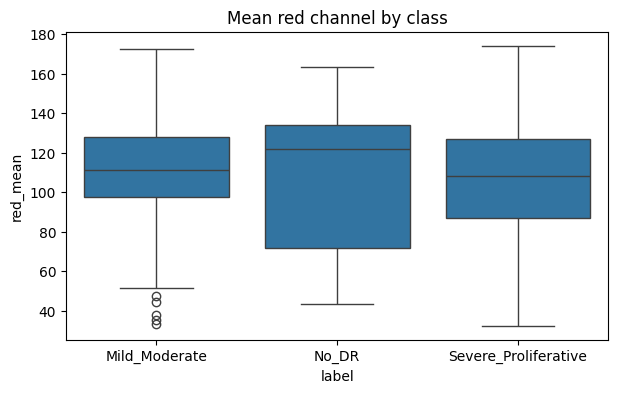

In [ ]:
from PIL import Image
import seaborn as sns

# Feature 1: class distribution (original 5 grades)
plt.figure(figsize=(7, 4))
df["original"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Images per original grade"); plt.ylabel("Count"); plt.show()

sample = df.groupby("label").sample(150, random_state=42).copy()
sample["brightness"] = sample["path"].apply(lambda p: np.array(Image.open(p).convert("L")).mean())
sample["red_mean"] = sample["path"].apply(lambda p: np.array(Image.open(p).convert("RGB"))[:, :, 0].mean())

# Feature 2: brightness per class
plt.figure(figsize=(7, 4))
sns.boxplot(data=sample, x="label", y="brightness")
plt.title("Image brightness by class"); plt.show()

# Feature 3: mean red channel per class
plt.figure(figsize=(7, 4))
sns.boxplot(data=sample, x="label", y="red_mean")
plt.title("Mean red channel by class"); plt.show()

**Feature 1: Class distribution.** No_DR has 1,805 images while Severe has only 193, roughly 9 to 1. A model that always guessed "healthy" would look decent on accuracy, so I used class weights and macro-F1.

**Feature 2: Brightness.** The medians are close for all three classes (about 68 to 73), and the boxes overlap heavily. No_DR has the widest spread. Brightness reflects camera and lighting, not disease, so it can't separate the classes.

**Feature 3: Mean red channel.** The medians are about 111 (Mild_Moderate), 122 (No_DR), and 108 (Severe). Severe is slightly lower, but the overlap is large. Simple colour averages tell us little, which is why a deep model that learns patterns like red dots and yellow patches is needed.

## 8. Saving the Model
Save the trained model and its settings for the API.

In [ ]:
import json
print("TF version:", tf.__version__)   # write this down for requirements

os.makedirs("/content/models", exist_ok=True)
model.save("/content/models/retina_model.keras")
try:
    model.save("/content/models/retina_model.h5")
except Exception as e:
    print("h5 save skipped:", e)

with open("/content/models/meta.json", "w") as f:
    json.dump({"class_names": class_names, "severe_weight": SEVERE_WEIGHT}, f)

TF version: 2.21.0


h5 save skipped: cannot pickle 'module' object


In [ ]:
def predict_image(path):
    img = np.array(Image.open(path).convert("RGB").resize((224, 224)), dtype="float32")
    prob = model.predict(np.expand_dims(img, 0), verbose=0)[0]
    idx = int(np.argmax(prob * np.array([1, 1, SEVERE_WEIGHT])))
    return class_names[idx], float(prob[idx])

for _, row in test_df.sample(5, random_state=1).iterrows():
    print("Actual:", row["label"], "| Predicted:", predict_image(row["path"]))

Actual: No_DR | Predicted: ('No_DR', 0.9777745008468628)
Actual: No_DR | Predicted: ('No_DR', 0.6826587319374084)
Actual: Mild_Moderate | Predicted: ('Mild_Moderate', 0.8210047483444214)
Actual: No_DR | Predicted: ('No_DR', 0.9988805651664734)
Actual: Mild_Moderate | Predicted: ('Mild_Moderate', 0.948862612247467)


In [ ]:
import shutil
trainval_df = pd.concat([train_df, val_df])
for split, frame in [("train", trainval_df), ("test", test_df)]:
    for c in class_names:
        os.makedirs(f"/content/project/data/{split}/{c}", exist_ok=True)
    for _, r in frame.iterrows():
        shutil.copy(r["path"], f"/content/project/data/{split}/{r['label']}/{os.path.basename(r['path'])}")

os.makedirs("/content/project/models", exist_ok=True)
shutil.copy("/content/models/retina_model.keras", "/content/project/models/")
shutil.copy("/content/models/meta.json", "/content/project/models/")
if os.path.exists("/content/models/retina_model.h5"):
    shutil.copy("/content/models/retina_model.h5", "/content/project/models/")

!zip -qr /content/project_assets.zip /content/project
from google.colab import files
files.download("/content/project_assets.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>